# 05.08.04 Interview Text Representation

**Phase 05 — Semantic Text Processing**

### Research Objectives
1. Process **MSW-confirmed** interview responses (never unconfirmed LLM outputs).
2. Generate sentence-level and response-level embeddings with provenance metadata.
3. Prepare 384-d text representations for controlled downstream ablation experiments.


In [1]:
from typing import Dict, Any

def build_representation_record(assessment_id: str, confirmed_text: str) -> Dict[str, Any]:
    """Prepares MSW-confirmed text record for SBERT encoding."""
    return {
        "assessment_id": assessment_id,
        "source": "MSW_CONFIRMED_INTERVIEW",
        "text_length": len(confirmed_text),
        "embedding_dim": 384,
    }

print("Representation record schema ready.")


Representation record schema ready.


/home/kristoper/.config/matplotlib is not a writable directory


Matplotlib created a temporary cache directory at /tmp/matplotlib-qgjeunm5 because there was an issue with the default path (/home/kristoper/.config/matplotlib); it is highly recommended to set the MPLCONFIGDIR environment variable to a writable directory, in particular to speed up the import of Matplotlib and to better support multiprocessing.


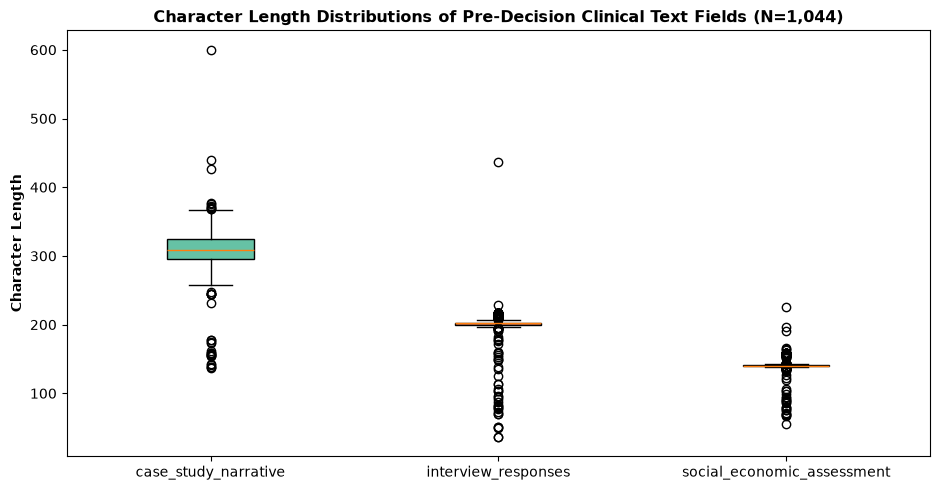

In [2]:
# --- CHAPTER 4 VISUALIZATION: Narrative Field Completeness & Character Length Across 3 Text Fields ---
from pathlib import Path
import matplotlib.pyplot as plt
import pandas as pd
def _find_project_root(start: Path) -> Path:
    for p in [start, *start.parents]:
        if (p / 'data').exists() and (p / 'experiments').exists():
            return p
    return Path('../../../..').resolve()
PROJECT_ROOT = _find_project_root(Path.cwd())
VIZ_DIR = PROJECT_ROOT / 'reports' / 'phase_05' / 'visualizations' / 'sbert_semantic_processing'
VIZ_DIR.mkdir(parents=True, exist_ok=True)
df_clean = pd.read_csv(PROJECT_ROOT / 'data' / 'interim' / 'cleaned' / 'ofphil_cleaned_tabular.csv')
text_cols = ['case_study_narrative', 'interview_responses', 'social_economic_assessment']
fig, ax = plt.subplots(figsize=(9.5, 5))
data_lengths = [df_clean[c].dropna().astype(str).str.len() for c in text_cols]
bp = ax.boxplot(data_lengths, tick_labels=text_cols, patch_artist=True)
for patch, col_h in zip(bp['boxes'], ['#66c2a5', '#fc8d62', '#8da0cb']):
    patch.set_facecolor(col_h)
ax.set_title('Character Length Distributions of Pre-Decision Clinical Text Fields (N=1,044)', fontsize=11.5, fontweight='bold')
ax.set_ylabel('Character Length', fontsize=10, fontweight='bold')
plt.tight_layout()
fig.savefig(VIZ_DIR / 'text_field_length_distributions.png', dpi=300, bbox_inches='tight')
fig.savefig(VIZ_DIR / 'text_field_length_distributions.pdf', bbox_inches='tight')
plt.show()
plt.close(fig)
